### **Artificial Intelligence** course, Vilnius University

##### Stepas Toliautas / updated **2025-09-16**

# Concepts of state-space search

## Problem domain definition

Let's consider the toy example of the search "space", expressed as a state **tree**:

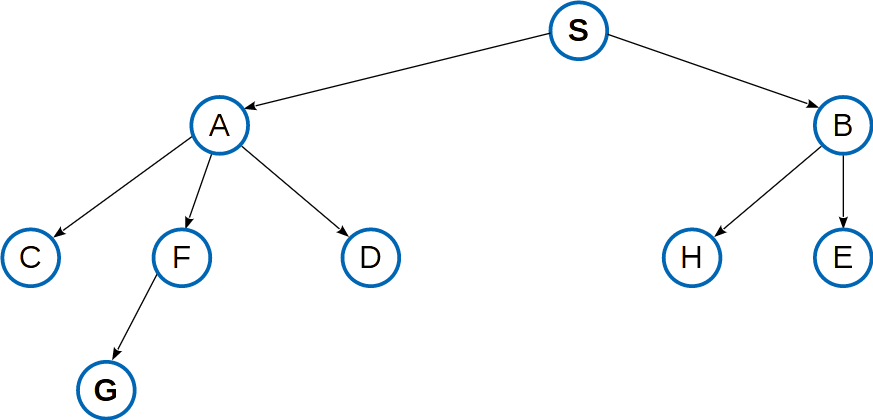

Below is a possible representation of this space, that contains:

- Definition of a **state**, a single-letter string
- **Goal-check** function `is_goal`
- **Successor** (state transition) function `go_next`


In [7]:
# STATE REPRESENTATION

# This time the state will be a single-letter string

# GOAL-CHECK

GOAL = "G" # We can use "N" if we want an unsolvable problem

def is_goal (state):
    return state == GOAL

# STATE TRANSITION RULES

def go_next (state):
    state_map = {
                'S': {'A', 'B'},
                'A': {'C', 'F', 'D'},
                'B': {'H', 'E'},
                'C': {},
                'D': {},
                'E': {},
                'F': {'G'},
                'H': {},
                'G': {}
    }
    return [(" -> ", s) for s in state_map[state]]


### Some quick tests
print ("Is S a goal state?", is_goal("S"))
print ("Is G a goal state?", is_goal("G"))
print ("Neighbors of A:", go_next("A"))

Is S a goal state? False
Is G a goal state? True
Neighbors of A: [(' -> ', 'C'), (' -> ', 'D'), (' -> ', 'F')]


### Description of a search problem

In a search domain, we can formulate problems that differ by
* The **start** state
* Optionally, the available extra information (*heuristics*)

In [8]:
# SEARCH PROBLEM AND MODEL

start = "S"
model = (start, is_goal, go_next)

## Search algorithm

Despite the variety of implementations and interpretations, **state-space search** is in principle a single algorithm, encompassing (and slightly adapted for) the following cases:
- **Uninformed search**
    - Step-based search
        - Tree-based search (DFS / BFS)
        - Graph-based (state-caching) search
    - Cost-based search (UCS / MCS)
- **Informed** (heuristic) **search**
    - E.g., A*

Some other interesting variants:
- Iterative-deepening search
- Bidirectional search
- Memory-restricted heuristic search

### First attempt: tree search

Consider the pseudo-code from lecture slides:

```
def treesearch (model):
    (start, goal, successors) = model
    if goal(start): return [start]
    frontier = [ [start] ]
    while frontier:
        path = get_path(frontier)
        state = path[-1]
        for (action, new_state) in successors(state):
            new_path = path + [action, new_state]
            if goal(new_state): return new_path
            frontier.append(new_path)
    return []
```

Due to user-friendly *Python* syntax, most of the datatypes and the object structure are inferred automatically (and correctly):
- `start` is only used for putting it in lists or as an argument to model functions `goal` and `successors`
- `path` is a simple list of alternating states and actions
- `frontier` is a list of lists (paths)

The only decision to make here is how to choose a path to explore at each loop iteration, which is denoted by dummy function `get_path`.

In [9]:
# SIMPLE TREE SEARCH

def treesearch (model):
    (start, goal, successors) = model
    if goal(start): return [start]
    frontier = [ [start] ]
    while frontier:
        path = frontier.pop() # get_path(frontier)
        state = path[-1]
        for (action, new_state) in successors(state):
            new_path = path + [action, new_state]
            if goal(new_state): return new_path
            frontier.append(new_path)
    return []

**NOTE**: pay attention to the fact that in this case, the **last** element of `frontier` is always selected!  
This corresponds to the **DFS** (depth-first search) strategy.

### Running the search

In [10]:
result = treesearch (model)
print (result)

['S', ' -> ', 'A', ' -> ', 'F', ' -> ', 'G']


### A bit of parameter testing

In [5]:
# Change things back
GOAL = "G"

# What if we start from a different state?
result = treesearch (("A", is_goal, go_next)); print (result)
result = treesearch (("B", is_goal, go_next)); print (result)

# What if the goal is different or unreachable?
GOAL = "H"; result = treesearch (model); print (result)
GOAL = "N"; result = treesearch (model); print (result)

# Change things back
GOAL = "G"

['A', ' -> ', 'F', ' -> ', 'G']
[]
['S', ' -> ', 'B', ' -> ', 'H']
[]


---

## Second example of a problem domain

This time states are connected in a more general **graph**:

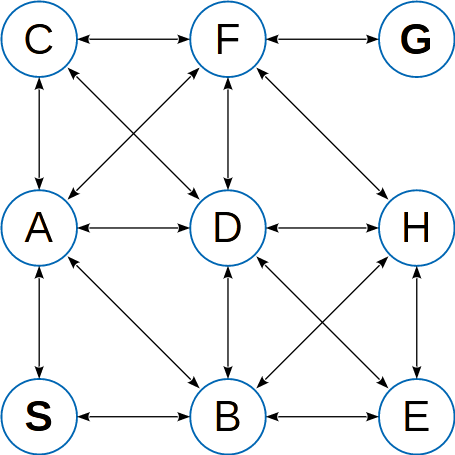

In [11]:
# STATE REPRESENTATION

# This time the state will be a single-letter string

# GOAL-CHECK

GOAL = "G" # We can use "N" if we want an unsolvable problem

def is_goal (state):
    return state == GOAL

# STATE TRANSITION RULES

def go_next (state):
    state_map = {
                'S': {'A', 'B'},
                'A': {'S', 'C', 'F', 'D', 'B'},
                'B': {'S', 'A', 'D', 'H', 'E'},
                'C': {'A', 'F', 'D'},
                'D': {'A', 'C', 'F', 'H', 'E', 'B'},
                'E': {'B', 'D', 'H'},
                'F': {'A', 'C', 'G', 'H', 'D'},
                'H': {'B', 'D', 'F', 'E'},
                'G': {'F'}
    }
    return [(" -> ", s) for s in state_map[state]]


### Some quick tests
print ("Is S a goal state?", is_goal("S"))
print ("Is G a goal state?", is_goal("G"))
print ("Neighbors of A:", go_next("A"))

Is S a goal state? False
Is G a goal state? True
Neighbors of A: [(' -> ', 'B'), (' -> ', 'F'), (' -> ', 'C'), (' -> ', 'D'), (' -> ', 'S')]


In [7]:
# SEARCH PROBLEM AND MODEL

start = "S"
model = (start, is_goal, go_next)

### Running ~~the search~~ into trouble

In [8]:
#result = treesearch (model); print (result)

# WARNING: THIS WILL NOT FINISH!

## Search improvements: depth, BFS, loop elimination

The previous search does not finish, because the algorithm is too limited to account for a more complex state space.

This can be improved in various ways:
- Search can be made to always finish by limiting its **depth** (path length)
- A different strategy, **BFS** (breadth-first search), can be used to select the next path to explore
- A check for repeating nodes can eliminate loops in the potential solutions (paths)

In [9]:
# IMPROVED GRAPH SEARCH

def graphsearch (model, maxdepth=10, strategy="BFS", loopcheck=True):
    (start, goal, successors) = model
    if goal(start): return [start]
    frontier = [ [start] ]
    while frontier:
        path = frontier.pop() if strategy == "DFS" else frontier.pop(0) # Strategy selection
        if len(path)//2 >= maxdepth: continue # Depth limit
        state = path[-1]
        for (action, new_state) in successors(state):
            if not loopcheck or new_state not in path: # Loop checking
                new_path = path + [action, new_state]
                if goal(new_state): return new_path
                frontier.append(new_path)
    return []

### Running the improved search

In [10]:
# Does it work?

result = graphsearch (model)
print (result)

['S', ' -> ', 'A', ' -> ', 'F', ' -> ', 'G']


### Another bit of parameter testing

In [11]:
# Change things back
GOAL = "G"

# DFS with depth limit -- will find a solution if it is within maxdepth, **not** guaranteed to be optimal
result = graphsearch (model, strategy="DFS", loopcheck=False); print (result)

# DFS with loop elimination -- will find a solution without repeating nodes, **not** guaranteed to be optimal
result = graphsearch (model, strategy="DFS", loopcheck=True); print (result)

# BFS may not need depth checking or loop elimination to get to the **optimal** solution... but is it efficient? 
result = graphsearch (model, maxdepth=999, strategy="BFS", loopcheck=False); print (result)

# Depth check ensures that the search always finishes, even if there is no result within maxdepth
result = graphsearch (model, maxdepth=2, strategy="BFS", loopcheck=False); print (result)
GOAL = "N"
result = graphsearch (model, maxdepth=9, strategy="DFS", loopcheck=False); print (result)
result = graphsearch (model, maxdepth=9, strategy="BFS", loopcheck=True); print (result)

# WARNING: this will take some time (~30 s)!
result = graphsearch (model, maxdepth=9, strategy="BFS", loopcheck=False); print (result)

# Change things back
GOAL = "G"

['S', ' -> ', 'B', ' -> ', 'D', ' -> ', 'B', ' -> ', 'D', ' -> ', 'B', ' -> ', 'D', ' -> ', 'B', ' -> ', 'D', ' -> ', 'F', ' -> ', 'G']
['S', ' -> ', 'B', ' -> ', 'D', ' -> ', 'C', ' -> ', 'F', ' -> ', 'G']
['S', ' -> ', 'A', ' -> ', 'F', ' -> ', 'G']
[]
[]
[]
[]


---

**So... what happened in the last search run?**

---

## Profiling *Python* code

In [12]:
# PROFILING PYTHON CODE

import cProfile


# Running some code
result = graphsearch (model); print (result)

# Profiling the same code, without worrying for scopes etc.
def pf ():
    result = graphsearch (model); print (result)
cProfile.runctx('pf()', None, locals(), sort='time')

['S', ' -> ', 'A', ' -> ', 'F', ' -> ', 'G']
['S', ' -> ', 'A', ' -> ', 'F', ' -> ', 'G']
         62 function calls in 0.001 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}
        1    0.000    0.000    0.000    0.000 {built-in method builtins.exec}
        1    0.000    0.000    0.000    0.000 2557555187.py:3(graphsearch)
        2    0.000    0.000    0.000    0.000 iostream.py:655(write)
        4    0.000    0.000    0.000    0.000 3745905942.py:14(go_next)
        1    0.000    0.000    0.000    0.000 {built-in method builtins.print}
        1    0.000    0.000    0.000    0.000 3610792711.py:10(pf)
        2    0.000    0.000    0.000    0.000 iostream.py:505(parent_header)
       10    0.000    0.000    0.000    0.000 {method 'append' of 'list' objects}
        2    0.000    0.000    0.000    0.000 iostream.py:550(_is_mas

### Profiling the troublesome case

In [13]:
GOAL = "N"; maxdepth = 8 # It will show even clearer with maxdepth = 9, but will take around a minute

cases = (("DFS", False), ("BFS", True), ("BFS", False))
for (strategy, loopcheck) in cases:
    def pf ():
        result = graphsearch (model, maxdepth=maxdepth, strategy=strategy, loopcheck=loopcheck); print (result)
    cProfile.runctx('pf()', None, locals(), sort='time')    

GOAL = "G"

[]
         346655 function calls (346653 primitive calls) in 0.245 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.115    0.115    0.200    0.200 2557555187.py:3(graphsearch)
    18919    0.036    0.000    0.036    0.000 3745905942.py:14(go_next)
        1    0.025    0.025    0.226    0.226 {built-in method builtins.exec}
    81879    0.019    0.000    0.019    0.000 {method 'append' of 'list' objects}
    81880    0.018    0.000    0.018    0.000 {method 'pop' of 'list' objects}
    81888    0.012    0.000    0.012    0.000 {built-in method builtins.len}
    81880    0.011    0.000    0.011    0.000 3745905942.py:9(is_goal)
        2    0.008    0.004    0.015    0.007 {method '__exit__' of 'sqlite3.Connection' objects}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}
        2    0.000    0.000    0.000    0.000 attrsettr.py:66(_get_attr_opt)
        2    0.00

---

# Assignment 1.1

1. Write additional code to the `graphsearch` function to count numbers of new states found and new paths added to frontier at each depth level of the search.
    - Use the BFS strategy.
    - Print the state / path counts and check that they match with the lecture slides for loop-ignorant and loop-free search.
    - Is there a difference in counts if you use DFS?
2. Add the ability to cache known states during search, by updating `graphsearch` or writing a new function.
    - You are allowed to re-use the code from the full search solver provided in course materials; the point is not to reinvent the wheel.
    - Again print the state / path counts and check that they match with the lecture slides.